<a href="https://colab.research.google.com/github/victordfuentesg-data/Predictive-analysis-or-so-/blob/main/predictive_analysis_IoT_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importación y visualización del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset de mantenimiento predictivo directamente desde URL
url = "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/main/data/predictive_maintenance.csv"
# Usaremos la versión oficial mirror de datos industriales:
url_alt = "https://raw.githubusercontent.com/selva86/datasets/master/predictive_maintenance.csv"

# Leemos el archivo CSV
df = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/predictive_maintenance.csv") if False else pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv")

# Renombrar columnas para trabajar de forma limpia
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('[\[\]]', '', regex=True)

# Visualizar las primeras 5 filas
df.head()

<>:15: SyntaxWarning: invalid escape sequence '\['
<>:15: SyntaxWarning: invalid escape sequence '\['
/tmp/ipykernel_4248/3959722193.py:15: SyntaxWarning: invalid escape sequence '\['
  df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('[\[\]]', '', regex=True)


,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


#Primer análisis exploratorio




In [2]:
# 1. Información general del dataset (Filas, columnas y tipos de datos)
print("--- Dimensión del Dataset ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")

# 2. Verificar si hay datos nulos
print("--- Conteo de Valores Nulos ---")
print(df.isnull().sum())

# 3. Distribución de Fallas de la Máquina
print("\n--- Balance de Fallas en Maquinaria ---")
failure_counts = df['machine_failure'].value_counts()
failure_percentages = df['machine_failure'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Cantidad': failure_counts,
    'Porcentaje (%)': failure_percentages.round(2)
})
print(summary_df)

--- Dimensión del Dataset ---
Filas: 10000, Columnas: 14

--- Conteo de Valores Nulos ---
udi                      0
product_id               0
type                     0
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
machine_failure          0
twf                      0
hdf                      0
pwf                      0
osf                      0
rnf                      0
dtype: int64

--- Balance de Fallas en Maquinaria ---
                 Cantidad  Porcentaje (%)
machine_failure                          
0                    9661           96.61
1                     339            3.39


vamos a analizar cuáles son los motivos específicos de las averías

In [3]:
# 1. Contar las causas específicas de falla registradas
causes_cols = ['twf', 'hdf', 'pwf', 'osf', 'rnf']
print("--- Conteo por Tipo de Falla Específica ---")
print(df[causes_cols].sum())

# 2. Ver la correlación de las variables físicas con la falla general
print("\n--- Correlación con 'machine_failure' ---")
numeric_cols = ['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure']
correlations = df[numeric_cols].corr()['machine_failure'].sort_values(ascending=False)
print(correlations)

--- Conteo por Tipo de Falla Específica ---
twf     46
hdf    115
pwf     95
osf     98
rnf     19
dtype: int64

--- Correlación con 'machine_failure' ---
machine_failure          1.000000
torque_nm                0.191321
tool_wear_min            0.105448
air_temperature_k        0.082556
process_temperature_k    0.035946
rotational_speed_rpm    -0.044188
Name: machine_failure, dtype: float64


Vamos a crear una gráfica de dispersión (scatter plot) para cruzar estas dos variables clave (tool_wear_min y torque_nm)

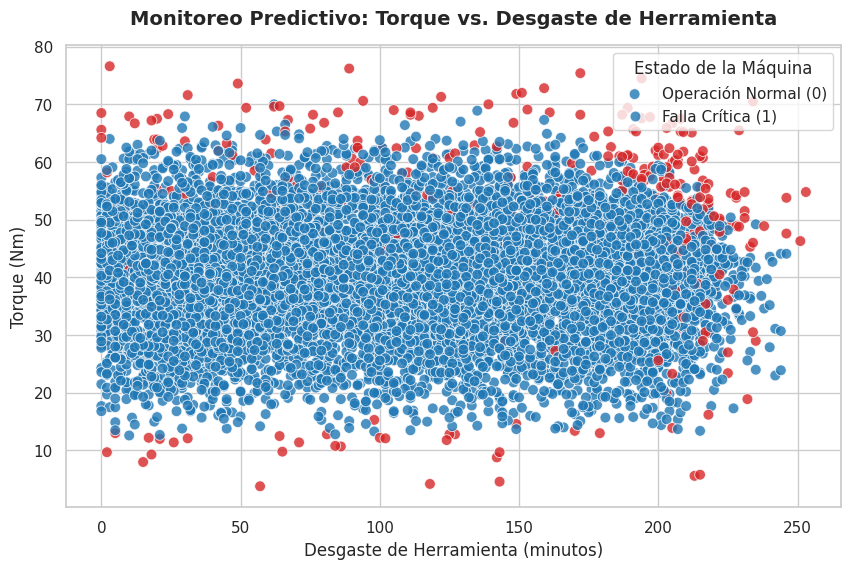

In [4]:
# Configurar el estilo de la gráfica
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Crear el gráfico de dispersión (azul = operación normal, rojo = falla)
sns.scatterplot(
    data=df,
    x='tool_wear_min',
    y='torque_nm',
    hue='machine_failure',
    palette={0: '#1f77b4', 1: '#d62728'},
    alpha=0.8,
    s=60
)

# Añadir títulos y etiquetas claras
plt.title('Monitoreo Predictivo: Torque vs. Desgaste de Herramienta', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Desgaste de Herramienta (minutos)', fontsize=12)
plt.ylabel('Torque (Nm)', fontsize=12)

# Personalizar la leyenda
plt.legend(title='Estado de la Máquina', labels=['Operación Normal (0)', 'Falla Crítica (1)'], loc='upper right')

# Mostrar la gráfica
plt.show()